# NYC WAV Service Risk: Statistical Modelling and Chronological Evaluation

> **MAST30034 Applied Data Science · Project 1**  
**Part 3: Issue-time feature engineering, Grouped Binomial GLM, Request-Weighted XGBoost, Held-Out Chronological Evaluation (Nov–Dec 2025), and Robustness Analyses.**

This notebook defines the strictly chronological forecast protocol, attaches frozen issue-time HRRR weather forecast features, trains and validates candidate models (Matured 24-hour persistence baseline, Grouped Binomial Logistic Regression, and Request-Weighted XGBoost), evaluates out-of-sample performance on the held-out November–December 2025 dataset, and performs comprehensive robustness and ablation checks.

## 1. Setup, Imports, and Configuration

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

In [3]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

print(f"Project root: {PROJECT_ROOT}")
print(f"Python executable: {sys.executable}")

Project root: /Users/lavenderle/project-1-individual-LavenderLe7
Python executable: /Users/lavenderle/project-1-individual-LavenderLe7/.venv/bin/python


In [4]:
RANDOM_SEED = 42
TIMEZONE = "America/New_York"

ANALYSIS_YEAR = 2025
ANALYSIS_MONTHS = tuple(range(4, 13))

ANALYSIS_START = "2025-04-01 00:00:00"
TRAIN_END_EXCLUSIVE = "2025-09-01 00:00:00"
VALIDATION_END_EXCLUSIVE = "2025-11-01 00:00:00"
ANALYSIS_END_EXCLUSIVE = "2026-01-01 00:00:00"
TEST_END_EXCLUSIVE = ANALYSIS_END_EXCLUSIVE

PERIOD_HOURS = 4
FORECAST_HORIZON_PERIODS = 1
DATA_MATURITY_BUFFER_PERIODS = 1
HISTORICAL_FEATURE_LAG_PERIODS = (
    FORECAST_HORIZON_PERIODS + DATA_MATURITY_BUFFER_PERIODS
)
LATE_THRESHOLD_MINUTES = 10
WAV_REQUEST_FLAG_VALUE = "Y"

NYC_BOROUGHS = (
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island",
)

HRRR_DATASET_ID = "noaa-hrrr-forecast-48-hour"
HRRR_INIT_START_UTC = "2025-03-31 00:00:00"
HRRR_INIT_END_UTC = "2026-01-01 06:00:00"
HRRR_INIT_FREQUENCY = "6h"
HRRR_FORECAST_AVAILABILITY_BUFFER_HOURS = 3
HRRR_DOWNLOAD_MAX_WORKERS = 8
HRRR_VARIABLES = (
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_surface",
    "categorical_rain_surface",
    "wind_u_10m",
    "wind_v_10m",
    "wind_gust_surface",
)

REPORT_FIGURE_DPI = 300
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

In [5]:
STANDARDIZED_DATA_ROOT = PROJECT_ROOT / "data" / "standardized"
CURATED_DATA_ROOT = PROJECT_ROOT / "data" / "curated"
CURATED_WAV_PANEL_PATH = (
    CURATED_DATA_ROOT
    / "wav_service_risk"
    / "borough_four_hour_panel.parquet"
)
HRRR_COMBINED_PATH = (
    STANDARDIZED_DATA_ROOT
    / "hrrr_forecasts"
    / "hrrr_borough_forecasts_standardized.parquet"
)

OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURE_OUTPUT_ROOT = OUTPUT_ROOT / "figures"
TABLE_OUTPUT_ROOT = OUTPUT_ROOT / "tables"
MODEL_OUTPUT_ROOT = OUTPUT_ROOT / "model_results"

for directory in (FIGURE_OUTPUT_ROOT, TABLE_OUTPUT_ROOT, MODEL_OUTPUT_ROOT):
    directory.mkdir(parents=True, exist_ok=True)


def save_report_figure(figure: plt.Figure, file_stem: str) -> None:
    """Save one report-ready figure in both PNG and PDF formats."""
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.png",
        dpi=REPORT_FIGURE_DPI,
        bbox_inches="tight",
    )
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.pdf",
        bbox_inches="tight",
    )

## 2. Ingest Curated Modelling Panel

In [6]:
# Load the curated borough-period modelling panel
saved_curated_wav_panel_df = pd.read_parquet(CURATED_WAV_PANEL_PATH)
print(f"Loaded curated panel: {len(saved_curated_wav_panel_df):,} rows × {len(saved_curated_wav_panel_df.columns):,} columns")

Loaded curated panel: 8,250 rows × 36 columns


# 7. Forecast design, feature engineering, and benchmark

Define the chronological split, forecast-time feature contracts, issue-time
HRRR alignment, matured-history benchmark, and evaluation metrics before
fitting either model family.

## 7.1 Chronological split and frozen feature contracts

Issue each rolling one-period-ahead forecast at the target-period start.
Completed-trip features use the lag-2 maturity rule. Both models use the
same calendar, matured-history, and target-period HRRR forecasts whose run
was available at least three hours before issue time.

### Shared model information set

The grouped-binomial GLM and weighted XGBoost use the same numerical
predictors and model-specific representations of the categorical context.
A later XGBoost ablation removes only the HRRR forecasts to assess their
incremental contribution without changing the main model comparison.

In [7]:
# Separate row identifiers and observed outcomes from predictors
MODEL_KEY_COLUMNS = (
    "period_start",
    "borough",
    "split_label",
)
MODEL_TARGET_COLUMNS = (
    "wav_request_count",
    "late_trip_count",
    "late_share",
)

# Use model-specific representations of the same categorical context
GLM_CATEGORICAL_FEATURES = (
    "borough_time_block",
    "day_of_week",
    "is_holiday",
)
XGB_CATEGORICAL_FEATURES = (
    "borough",
    "time_block",
    "day_of_week",
    "is_holiday",
)

CALENDAR_MODEL_FEATURES = (
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
)
HISTORICAL_MODEL_FEATURES = (
    "log1p_lag_2_wav_request_count",
    "log1p_rolling_24h_wav_request_count",
    "log1p_lag_2_citywide_wav_request_count",
    "lag_2_late_share",
    "rolling_24h_late_share",
    "rolling_7d_late_share",
    "historical_same_slot_late_share",
    "lag_2_late_share_available",
    "rolling_24h_late_share_available",
    "rolling_7d_late_share_available",
    "same_slot_late_share_available",
)
HRRR_SOURCE_WEATHER_COLUMNS = (
    "temperature_2m_c",
    "relative_humidity_2m_pct",
    "precipitation_rate_mm_per_hour",
    "categorical_rain",
    "wind_speed_10m_ms",
    "wind_gust_ms",
)
HRRR_FORECAST_MODEL_FEATURES = (
    "hrrr_forecast_mean_temperature_c",
    "hrrr_forecast_mean_relative_humidity_pct",
    "hrrr_forecast_total_precipitation_mm",
    "hrrr_forecast_any_rain",
    "hrrr_forecast_mean_wind_speed_ms",
    "hrrr_forecast_max_wind_gust_ms",
)
WITHOUT_HRRR_NUMERIC_MODEL_FEATURES = (
    *CALENDAR_MODEL_FEATURES,
    *HISTORICAL_MODEL_FEATURES,
)
MODEL_NUMERIC_FEATURES = (
    *WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    *HRRR_FORECAST_MODEL_FEATURES,
)
ALL_MODEL_PREDICTOR_COLUMNS = tuple(
    dict.fromkeys(
        GLM_CATEGORICAL_FEATURES
        + XGB_CATEGORICAL_FEATURES
        + MODEL_NUMERIC_FEATURES
    )
)
PANEL_MODEL_PREDICTOR_COLUMNS = tuple(
    feature_name
    for feature_name in ALL_MODEL_PREDICTOR_COLUMNS
    if feature_name != "borough_time_block"
)

## 7.2 Issue-time HRRR feature engineering

Select the latest run satisfying `init_time + 3 hours <= period_start`,
then aggregate only that run's valid-time weather inside the target borough-
period. Run selection uses timestamps and forecast metadata only.

In [8]:
hrrr_forecast_source_df = pd.read_parquet(HRRR_COMBINED_PATH)
print(f"HRRR forecast rows: {len(hrrr_forecast_source_df):,}")

HRRR forecast rows: 270,970


In [9]:
# Standardise forecast timestamps before temporal alignment
hrrr_forecast_source_df = hrrr_forecast_source_df.copy()
for timestamp_column in ("init_time_utc", "valid_time_utc"):
    hrrr_forecast_source_df[timestamp_column] = pd.to_datetime(
        hrrr_forecast_source_df[timestamp_column],
        utc=True,
    )

In [10]:
# Build one target-period schedule without using target outcomes
hrrr_target_period_df = (
    saved_curated_wav_panel_df[["period_start"]]
    .drop_duplicates()
    .sort_values("period_start")
    .reset_index(drop=True)
)
hrrr_target_period_df["period_start"] = pd.to_datetime(
    hrrr_target_period_df["period_start"]
)
hrrr_target_period_df["period_end"] = (
    hrrr_target_period_df["period_start"]
    + pd.to_timedelta(PERIOD_HOURS, unit="h")
)
# Localise both boundaries separately to preserve daylight-saving changes
hrrr_target_period_df["period_start_utc"] = (
    hrrr_target_period_df["period_start"]
    .dt.tz_localize(TIMEZONE)
    .dt.tz_convert("UTC")
)
hrrr_target_period_df["period_end_utc"] = (
    hrrr_target_period_df["period_end"]
    .dt.tz_localize(TIMEZONE)
    .dt.tz_convert("UTC")
)
hrrr_target_period_df["forecast_availability_cutoff_utc"] = (
    hrrr_target_period_df["period_start_utc"]
    - pd.to_timedelta(
        HRRR_FORECAST_AVAILABILITY_BUFFER_HOURS,
        unit="h",
    )
)

hrrr_available_run_df = (
    hrrr_forecast_source_df[["init_time_utc"]]
    .drop_duplicates()
    .sort_values("init_time_utc")
)
hrrr_selected_run_df = pd.merge_asof(
    hrrr_target_period_df.sort_values(
        "forecast_availability_cutoff_utc"
    ),
    hrrr_available_run_df,
    left_on="forecast_availability_cutoff_utc",
    right_on="init_time_utc",
    direction="backward",
    allow_exact_matches=True,
).rename(columns={"init_time_utc": "selected_init_time_utc"})
hrrr_selected_run_df["forecast_age_hours"] = (
    hrrr_selected_run_df["period_start_utc"]
    - hrrr_selected_run_df["selected_init_time_utc"]
) / pd.to_timedelta(1, unit="h")

hrrr_selected_run_df[[
    "period_start",
    "selected_init_time_utc",
    "forecast_age_hours",
]].head()

,period_start,selected_init_time_utc,forecast_age_hours
0,2025-04-01 00:00:00,2025-04-01 00:00:00+00:00,4.0000
1,2025-04-01 04:00:00,2025-04-01 00:00:00+00:00,8.0000
2,2025-04-01 08:00:00,2025-04-01 06:00:00+00:00,6.0000
3,2025-04-01 12:00:00,2025-04-01 12:00:00+00:00,4.0000
4,2025-04-01 16:00:00,2025-04-01 12:00:00+00:00,8.0000


In [11]:
# Expand target periods to boroughs, then join only the selected run
hrrr_borough_df = (
    saved_curated_wav_panel_df[["borough"]]
    .drop_duplicates()
    .sort_values("borough")
)
hrrr_borough_period_df = hrrr_selected_run_df.merge(
    hrrr_borough_df,
    how="cross",
)
hrrr_selected_source_df = hrrr_forecast_source_df.rename(
    columns={"init_time_utc": "selected_init_time_utc"}
)
# One run can serve adjacent periods before valid-time filtering
hrrr_target_hourly_df = hrrr_borough_period_df.merge(
    hrrr_selected_source_df,
    on=["selected_init_time_utc", "borough"],
    how="left",
)
hrrr_target_hourly_df = hrrr_target_hourly_df.loc[
    hrrr_target_hourly_df["valid_time_utc"].ge(
        hrrr_target_hourly_df["period_start_utc"]
    )
    & hrrr_target_hourly_df["valid_time_utc"].lt(
        hrrr_target_hourly_df["period_end_utc"]
    )
].copy()
hrrr_period_key_columns = ("period_start", "borough")
hrrr_actual_hour_count = hrrr_target_hourly_df.groupby(
    list(hrrr_period_key_columns),
    observed=True,
).size()
hrrr_expected_hour_count = (
    hrrr_borough_period_df.set_index(list(hrrr_period_key_columns))[
        "period_end_utc"
    ]
    - hrrr_borough_period_df.set_index(list(hrrr_period_key_columns))[
        "period_start_utc"
    ]
) / pd.to_timedelta(1, unit="h")
hrrr_expected_hour_count = hrrr_expected_hour_count.astype(int)
hrrr_hour_count_comparison_df = pd.concat(
    [
        hrrr_expected_hour_count.rename("expected_hour_count"),
        hrrr_actual_hour_count.rename("actual_hour_count"),
    ],
    axis=1,
)
hrrr_hour_count_comparison_df.value_counts().sort_index()

expected_hour_count  actual_hour_count
4                    4                    8245
5                    5                       5
Name: count, dtype: int64

In [12]:
# Aggregate valid-time forecasts into one feature row per borough-period
hrrr_forecast_feature_df = (
    hrrr_target_hourly_df.groupby(
        list(hrrr_period_key_columns),
        observed=True,
    )
    .agg(
        hrrr_forecast_mean_temperature_c=(
            "temperature_2m_c",
            "mean",
        ),
        hrrr_forecast_mean_relative_humidity_pct=(
            "relative_humidity_2m_pct",
            "mean",
        ),
        hrrr_forecast_total_precipitation_mm=(
            "precipitation_rate_mm_per_hour",
            "sum",
        ),
        hrrr_forecast_any_rain=("categorical_rain", "max"),
        hrrr_forecast_mean_wind_speed_ms=(
            "wind_speed_10m_ms",
            "mean",
        ),
        hrrr_forecast_max_wind_gust_ms=("wind_gust_ms", "max"),
        hrrr_selected_init_time_utc=("selected_init_time_utc", "first"),
        hrrr_forecast_age_hours=("forecast_age_hours", "first"),
        hrrr_forecast_hour_count=("valid_time_utc", "size"),
        hrrr_minimum_lead_hours=("lead_time_hours", "min"),
        hrrr_maximum_lead_hours=("lead_time_hours", "max"),
    )
    .reset_index()
)

## 7.3 Model-ready chronological frames

Join the complete HRRR feature table one-to-one to the base panel. Keep
outcomes only in training and validation frames, and construct the future
evaluation frame from keys and forecast-time predictors alone.

In [13]:
def add_borough_time_block(data: pd.DataFrame) -> pd.DataFrame:
    """Add the pre-specified borough and four-hour interaction category."""
    enriched_data = data.copy()
    enriched_data["borough_time_block"] = (
        enriched_data["borough"].astype("string")
        + " | "
        + enriched_data["time_block"].astype("string")
    )
    return enriched_data

In [14]:
# Attach complete issue-time forecast features to the base panel
model_panel_df = saved_curated_wav_panel_df.merge(
    hrrr_forecast_feature_df[
        [
            *hrrr_period_key_columns,
            *HRRR_FORECAST_MODEL_FEATURES,
        ]
    ],
    on=list(hrrr_period_key_columns),
    how="left",
)
development_model_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS
        + MODEL_TARGET_COLUMNS
        + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)
future_feature_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)

training_model_mask = (
    model_panel_df["split_label"].eq("training")
    & model_panel_df["target_observed"]
)
validation_model_mask = (
    model_panel_df["split_label"].eq("validation")
    & model_panel_df["target_observed"]
)
future_test_mask = model_panel_df["split_label"].eq("test")

model_training_df = add_borough_time_block(
    model_panel_df.loc[
        training_model_mask,
        development_model_columns,
    ]
)
model_validation_df = add_borough_time_block(
    model_panel_df.loc[
        validation_model_mask,
        development_model_columns,
    ]
)
future_test_features_df = add_borough_time_block(
    model_panel_df.loc[
        future_test_mask,
        future_feature_columns,
    ]
)
model_development_df = pd.concat(
    [model_training_df, model_validation_df],
    ignore_index=True,
)

In [15]:
split_summary_df = pd.DataFrame(
    [
        {
            "split": "Training",
            "period": "April-August 2025",
            "panel_rows": int(
                model_panel_df["split_label"].eq("training").sum()
            ),
            "scoreable_rows": len(model_training_df),
        },
        {
            "split": "Validation",
            "period": "September-October 2025",
            "panel_rows": int(
                model_panel_df["split_label"].eq("validation").sum()
            ),
            "scoreable_rows": len(model_validation_df),
        },
        {
            "split": "Chronological evaluation",
            "period": "November-December 2025",
            "panel_rows": len(future_test_features_df),
            "scoreable_rows": pd.NA,
        },
    ]
)
split_summary_df

,split,period,panel_rows,scoreable_rows
0,Training,April-August 2025,4590,4438
1,Validation,September-October 2025,1830,1734
2,Chronological evaluation,November-December 2025,1830,<NA>


## 7.4 Matured 24-hour history benchmark

Create a count-weighted forecast from the latest mature 24-hour history
ending four hours before issue time, with training-period borough and
citywide fallbacks.

In [16]:
# Estimate borough and citywide fallback risks from training data only
training_borough_fallback_df = (
    model_training_df
    .groupby("borough", as_index=False)
    .agg(
        late_trip_count=("late_trip_count", "sum"),
        wav_request_count=("wav_request_count", "sum"),
    )
)
training_borough_fallback_df["borough_training_late_share"] = (
    training_borough_fallback_df["late_trip_count"]
    / training_borough_fallback_df["wav_request_count"]
)
training_global_late_share = (
    model_training_df["late_trip_count"].sum()
    / model_training_df["wav_request_count"].sum()
)

In [17]:
BENCHMARK_PREDICTION_COLUMNS = {
    "Matured 24-hour history": "persistence_24h_prediction",
}
benchmark_source_columns = (
    *MODEL_KEY_COLUMNS,
    "rolling_24h_late_share",
)
# Assemble target-free validation and test rows for benchmark forecasts
benchmark_forecast_source_df = pd.concat(
    [
        model_validation_df.loc[:, benchmark_source_columns],
        future_test_features_df.loc[:, benchmark_source_columns],
    ],
    ignore_index=True,
)
benchmark_forecast_source_df = benchmark_forecast_source_df.merge(
    training_borough_fallback_df[
        ["borough", "borough_training_late_share"]
    ],
    on="borough",
    how="left",
)

# Fall back from matured 24-hour history to borough and global risk
borough_fallback_values = benchmark_forecast_source_df[
    "borough_training_late_share"
].fillna(training_global_late_share)
benchmark_forecast_source_df["persistence_24h_prediction"] = (
    benchmark_forecast_source_df["rolling_24h_late_share"]
    .fillna(borough_fallback_values)
)

# Retain keys and forecasts only
benchmark_output_columns = (
    *MODEL_KEY_COLUMNS,
    *BENCHMARK_PREDICTION_COLUMNS.values(),
)
benchmark_forecasts_df = (
    benchmark_forecast_source_df.loc[:, benchmark_output_columns]
    .sort_values(["period_start", "borough"])
    .reset_index(drop=True)
)

## 7.5 Evaluation criteria

Use request-weighted MAE as the primary comparison metric and retain
weighted RMSE, unweighted MAE, calibration, and subgroup diagnostics.

In [18]:
# Freeze calibration, screening, and robustness criteria
PRIMARY_SELECTION_METRIC = "weighted_mae"
HIGH_RISK_THRESHOLD = 0.10
CALIBRATION_BIN_COUNT = 10
TOP_RISK_CAPTURE_SHARE = 0.10
REQUEST_VOLUME_BIN_EDGES = (0, 10, 50, 100, np.inf)
REQUEST_VOLUME_BIN_LABELS = (
    "1-10 requests",
    "11-50 requests",
    "51-100 requests",
    "More than 100 requests",
)

In [19]:
def calculate_forecast_metrics(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    evaluation_group: str = "Overall",
) -> dict[str, float | int | str]:
    """
    Calculate count-weighted and unweighted forecast-error metrics.

    Args:
        evaluation_data: Scoreable rows with targets, weights, and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Human-readable model or benchmark name.
        evaluation_group: Population label for the returned record.

    Returns:
        One metric record containing errors, calibration, and support.
    """
    # Align grouped outcomes, forecasts, and request-count weights
    observed_values = evaluation_data["late_share"].to_numpy(
        dtype=float
    )
    predicted_values = evaluation_data[prediction_column].to_numpy(
        dtype=float
    )
    request_weights = evaluation_data["wav_request_count"].to_numpy(
        dtype=float
    )
    split_label = str(evaluation_data["split_label"].iloc[0])

    # Use request-weighted MAE as primary, with supporting error measures
    weighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    weighted_rmse = root_mean_squared_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    unweighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
    )
    observed_weighted_share = np.average(
        observed_values,
        weights=request_weights,
    )
    predicted_weighted_share = np.average(
        predicted_values,
        weights=request_weights,
    )

    return {
        "model_name": model_name,
        "split_label": split_label,
        "evaluation_group": evaluation_group,
        "row_count": len(evaluation_data),
        "wav_request_count": int(request_weights.sum()),
        "weighted_mae": weighted_mae,
        "weighted_mae_percentage_points": 100 * weighted_mae,
        "weighted_rmse": weighted_rmse,
        "weighted_rmse_percentage_points": 100 * weighted_rmse,
        "unweighted_mae": unweighted_mae,
        "unweighted_mae_percentage_points": 100 * unweighted_mae,
        "observed_weighted_late_share": observed_weighted_share,
        "predicted_weighted_late_share": predicted_weighted_share,
        "calibration_gap_percentage_points": (
            100
            * (predicted_weighted_share - observed_weighted_share)
        ),
    }

In [20]:
def build_weighted_calibration_table(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    bin_count: int = CALIBRATION_BIN_COUNT,
) -> pd.DataFrame:
    """
    Summarise observed and predicted risk in weighted forecast-risk bins.

    Args:
        evaluation_data: Scoreable rows with grouped outcomes and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Label recorded in the returned table.
        bin_count: Number of equal-row forecast-risk groups.

    Returns:
        One row per calibration bin with request-weighted risk estimates.
    """
    # Rank forecasts before forming equal-row risk bins
    calibration_data = evaluation_data.copy()
    forecast_ranks = calibration_data[prediction_column].rank(
        method="first"
    )
    calibration_data["calibration_bin"] = (
        pd.qcut(
            forecast_ranks,
            q=bin_count,
            labels=False,
        )
        + 1
    )
    # Weight predicted risk by completed-request support within each bin
    calibration_data["weighted_prediction_total"] = (
        calibration_data[prediction_column]
        * calibration_data["wav_request_count"]
    )

    calibration_table = (
        calibration_data
        .groupby("calibration_bin", as_index=False, observed=True)
        .agg(
            row_count=("period_start", "size"),
            wav_request_count=("wav_request_count", "sum"),
            late_trip_count=("late_trip_count", "sum"),
            mean_predicted_risk=(
                "weighted_prediction_total",
                "sum",
            ),
            minimum_prediction=(prediction_column, "min"),
            maximum_prediction=(prediction_column, "max"),
        )
    )
    calibration_table["observed_late_share"] = (
        calibration_table["late_trip_count"]
        / calibration_table["wav_request_count"]
    )
    calibration_table["predicted_late_share"] = (
        calibration_table["mean_predicted_risk"]
        / calibration_table["wav_request_count"]
    )
    calibration_table.insert(0, "model_name", model_name)
    return calibration_table.drop(columns="mean_predicted_risk")

In [21]:
# Join validation outcomes to the target-free history benchmark
validation_benchmark_scoring_df = (
    model_validation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ]
    .merge(
        benchmark_forecasts_df.loc[
            benchmark_forecasts_df["split_label"].eq("validation")
        ],
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)

validation_benchmark_metrics_df = pd.DataFrame(
    [
        calculate_forecast_metrics(
            validation_benchmark_scoring_df,
            prediction_column,
            benchmark_name,
        )
        for benchmark_name, prediction_column in (
            BENCHMARK_PREDICTION_COLUMNS.items()
        )
    ]
)
validation_benchmark_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points
0,Matured 24-hour history,2.9676,4.3203,5.4294


# 8. Model training and validation

Fit one grouped-binomial GLM and one weighted XGBoost using the shared
model information set. Validation compares the model families and freezes
the XGBoost tree count before chronological evaluation.

## 8.1 Model 1: Grouped Binomial Logistic Regression

Model each borough-period through its grouped late and on-time completed-trip counts using a binomial likelihood.

### 8.1.1 Model specification

Fit training-only imputation, scaling, and reference-level encoding before
constructing a full-rank grouped-binomial design matrix.

In [22]:
GLM_MODEL_NAME = "Grouped Binomial GLM"
XGB_MODEL_NAME = "Weighted XGBoost"
GLM_CLUSTER_FREQUENCY = "W-SUN"

model_feature_contract_df = pd.DataFrame(
    [
        {
            "model_name": GLM_MODEL_NAME,
            "categorical_feature_count": len(
                GLM_CATEGORICAL_FEATURES
            ),
            "numeric_feature_count": len(MODEL_NUMERIC_FEATURES),
        },
        {
            "model_name": XGB_MODEL_NAME,
            "categorical_feature_count": len(
                XGB_CATEGORICAL_FEATURES
            ),
            "numeric_feature_count": len(MODEL_NUMERIC_FEATURES),
        },
    ]
)
model_feature_contract_df

,model_name,categorical_feature_count,numeric_feature_count
0,Grouped Binomial GLM,3,20
1,Weighted XGBoost,4,20


In [23]:
def build_model_preprocessor(
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    *,
    standardise_numeric: bool,
    drop_first_category: bool,
) -> ColumnTransformer:
    """
    Build a training-fitted preprocessing pipeline for model predictors.

    Args:
        categorical_features: Categorical columns to impute and encode.
        numeric_features: Numerical columns to impute and optionally scale.
        standardise_numeric: Whether to centre and scale numerical columns.
        drop_first_category: Whether to omit one reference category per factor.

    Returns:
        An unfitted column transformer with deterministic feature names.
    """
    # Impute and one-hot encode categories using training data only
    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "encoder",
                OneHotEncoder(
                    drop="first" if drop_first_category else None,
                    sparse_output=False,
                ),
            ),
        ]
    )

    # Median-impute numeric fields and scale them only when requested
    numeric_steps = [
        (
            "imputer",
            SimpleImputer(strategy="median"),
        )
    ]
    if standardise_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    # Preserve readable output feature names for model interpretation
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_pipeline,
                list(categorical_features),
            ),
            ("numeric", Pipeline(numeric_steps), list(numeric_features)),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

In [24]:
def build_grouped_binomial_outcome(
    modelling_data: pd.DataFrame,
) -> np.ndarray:
    """
    Construct explicit grouped late and on-time counts for a binomial GLM.

    Args:
        modelling_data: Scoreable borough-period rows with grouped counts.

    Returns:
        A two-column array containing late and on-time completed trips.
    """
    late_counts = modelling_data["late_trip_count"].to_numpy(dtype=float)
    request_counts = modelling_data["wav_request_count"].to_numpy(
        dtype=float
    )
    # A grouped binomial outcome stores event and non-event counts
    on_time_counts = request_counts - late_counts

    return np.column_stack([late_counts, on_time_counts])

In [25]:
def fit_grouped_binomial_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
) -> dict[str, object]:
    """
    Fit a grouped-binomial GLM and predict a later chronological period.

    The encoder, imputer, and scaler are fitted only on fitting_data. Weekly
    cluster-robust covariance is used for coefficient uncertainty, while
    predictions follow the grouped-binomial mean model.

    Args:
        fitting_data: Rows containing predictors and grouped outcomes.
        prediction_data: Later rows requiring probability forecasts.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.

    Returns:
        Fitted preprocessing and GLM objects, forecasts, and diagnostics.
    """
    # Fit all preprocessing on the historical fitting rows only
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=True,
        drop_first_category=True,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    feature_names = tuple(preprocessor.get_feature_names_out())

    # Construct named design matrices and add the intercept explicitly
    fitting_design = pd.DataFrame(
        fitting_matrix,
        columns=feature_names,
        index=fitting_data.index,
    )
    prediction_design = pd.DataFrame(
        prediction_matrix,
        columns=feature_names,
        index=prediction_data.index,
    )
    fitting_design = sm.add_constant(
        fitting_design,
        has_constant="add",
    )
    prediction_design = sm.add_constant(
        prediction_design,
        has_constant="add",
    )

    # Remove exact duplicate columns so the GLM design is estimable
    duplicate_column_mask = fitting_design.T.duplicated(
        keep="first"
    )
    dropped_duplicate_columns = tuple(
        fitting_design.columns[duplicate_column_mask]
    )
    fitting_design = fitting_design.loc[:, ~duplicate_column_mask]
    prediction_design = prediction_design.loc[
        :, ~duplicate_column_mask
    ]

    design_rank = int(
        np.linalg.matrix_rank(fitting_design.to_numpy(dtype=float))
    )
    # Cluster coefficient uncertainty by calendar week
    grouped_outcome = build_grouped_binomial_outcome(fitting_data)
    cluster_groups = (
        fitting_data["period_start"]
        .dt.to_period(GLM_CLUSTER_FREQUENCY)
        .astype(str)
    )
    glm_model = sm.GLM(
        endog=grouped_outcome,
        exog=fitting_design,
        family=sm.families.Binomial(),
    )
    glm_result = glm_model.fit(
        cov_type="cluster",
        cov_kwds={"groups": cluster_groups},
    )

    # Generate later-period probability forecasts
    predicted_probabilities = np.asarray(
        glm_result.predict(prediction_design),
        dtype=float,
    )
    pearson_dispersion = float(
        np.square(glm_result.resid_pearson).sum()
        / glm_result.df_resid
    )
    return {
        "preprocessor": preprocessor,
        "result": glm_result,
        "fitting_design": fitting_design,
        "prediction_design": prediction_design,
        "predictions": predicted_probabilities,
        "design_rank": design_rank,
        "parameter_count": fitting_design.shape[1],
        "cluster_count": int(cluster_groups.nunique()),
        "dropped_duplicate_columns": (
            dropped_duplicate_columns
        ),
        "pearson_dispersion": pearson_dispersion,
    }

In [26]:
GLM_VALIDATION_PREDICTION_COLUMN = "glm_validation_prediction"

glm_validation_fit = fit_grouped_binomial_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=GLM_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
)
glm_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
glm_validation_scoring_df[GLM_VALIDATION_PREDICTION_COLUMN] = (
    glm_validation_fit["predictions"]
)
glm_validation_metric_record = calculate_forecast_metrics(
    glm_validation_scoring_df,
    GLM_VALIDATION_PREDICTION_COLUMN,
    GLM_MODEL_NAME,
)
glm_validation_metric_record.update(
    {
        "parameter_count": glm_validation_fit["parameter_count"],
        "selected_tree_count": pd.NA,
    }
)

In [27]:
glm_validation_metrics_df = pd.DataFrame(
    [glm_validation_metric_record]
)
glm_validation_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "parameter_count",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,parameter_count
0,Grouped Binomial GLM,2.6065,3.7541,56


## 8.2 Model 2: Weighted XGBoost

Fit a nonlinear logistic-objective XGBoost regressor using completed-request
counts as observation weights.

### 8.2.1 Validation and early stopping

Use the frozen regularised hyperparameters with validation-based early
stopping. The selected tree count is fixed before chronological evaluation.

In [28]:
XGB_N_JOBS = 4
XGB_MAX_ESTIMATORS = 3000
XGB_EARLY_STOPPING_ROUNDS = 100
XGB_REGULARISED_CONFIGURATION = {
    "max_depth": 2,
    "learning_rate": 0.05,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
}

In [29]:
def build_xgboost_model(
    configuration: dict[str, float | int | str],
    n_estimators: int,
    early_stopping_rounds: int | None = None,
) -> XGBRegressor:
    """
    Build an XGBoost regressor from one frozen configuration.

    Args:
        configuration: Frozen feature and hyperparameter settings.
        n_estimators: Maximum or selected number of boosting trees.
        early_stopping_rounds: Optional validation stopping patience.

    Returns:
        An unfitted, reproducibly configured XGBoost estimator.
    """
    model_parameters = {
        "objective": "reg:logistic",
        "n_estimators": n_estimators,
        "eval_metric": "mae",
        "random_state": RANDOM_SEED,
        "n_jobs": XGB_N_JOBS,
        "tree_method": "hist",
        "max_depth": configuration["max_depth"],
        "learning_rate": configuration["learning_rate"],
        "min_child_weight": configuration["min_child_weight"],
        "subsample": configuration["subsample"],
        "colsample_bytree": configuration["colsample_bytree"],
        "reg_lambda": configuration["reg_lambda"],
    }
    # Add validation-based stopping only when early stopping is requested
    if early_stopping_rounds is not None:
        model_parameters["early_stopping_rounds"] = (
            early_stopping_rounds
        )
    return XGBRegressor(**model_parameters)

In [30]:
def fit_xgboost_validation_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    configuration: dict[str, float | int | str],
) -> dict[str, object]:
    """Fit one weighted XGBoost validation model with early stopping.

    Args:
        fitting_data: April-August scoreable rows.
        prediction_data: September-October scoreable rows.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.
        configuration: Frozen regularised hyperparameters.

    Returns:
        Fitted preprocessor and model, forecasts, and tree count.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=False,
        drop_first_category=False,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    model = build_xgboost_model(
        configuration=configuration,
        n_estimators=XGB_MAX_ESTIMATORS,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
    )
    model.fit(
        fitting_matrix,
        fitting_data["late_share"],
        sample_weight=fitting_data["wav_request_count"],
        eval_set=[
            (prediction_matrix, prediction_data["late_share"])
        ],
        sample_weight_eval_set=[
            prediction_data["wav_request_count"]
        ],
        verbose=False,
    )
    predictions = model.predict(prediction_matrix)
    return {
        "preprocessor": preprocessor,
        "model": model,
        "predictor_columns": predictor_columns,
        "predictions": predictions,
        "selected_tree_count": int(model.best_iteration + 1),
    }

In [31]:
XGB_VALIDATION_PREDICTION_COLUMN = "xgb_validation_prediction"

xgb_validation_fit = fit_xgboost_validation_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
)
xgb_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
xgb_validation_scoring_df[XGB_VALIDATION_PREDICTION_COLUMN] = (
    xgb_validation_fit["predictions"]
)
xgb_validation_metric_record = calculate_forecast_metrics(
    xgb_validation_scoring_df,
    XGB_VALIDATION_PREDICTION_COLUMN,
    XGB_MODEL_NAME,
)
xgb_validation_metric_record.update(
    {
        "parameter_count": pd.NA,
        "selected_tree_count": xgb_validation_fit[
            "selected_tree_count"
        ],
    }
)
xgb_validation_metrics_df = pd.DataFrame(
    [xgb_validation_metric_record]
)
xgb_validation_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "selected_tree_count",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,selected_tree_count
0,Weighted XGBoost,2.5496,3.7250,125


### 8.2.2 Frozen validation summary

Compare the two model families with the matured-history benchmark, then
freeze the validation-selected XGBoost tree count before evaluation.

In [32]:
XGB_TREE_COUNT = int(
    xgb_validation_fit["selected_tree_count"]
)

validation_comparison_records = [
    *validation_benchmark_metrics_df.to_dict(orient="records"),
    glm_validation_metric_record,
    xgb_validation_metric_record,
]
validation_model_comparison_df = (
    pd.DataFrame(validation_comparison_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
print(f"Frozen Weighted XGBoost trees: {XGB_TREE_COUNT}")
validation_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "calibration_gap_percentage_points",
        "selected_tree_count",
    ]
]

Frozen Weighted XGBoost trees: 125


,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,calibration_gap_percentage_points,selected_tree_count
0,Weighted XGBoost,2.5496,3.7250,-0.5461,125
1,Grouped Binomial GLM,2.6065,3.7541,-0.4282,<NA>
2,Matured 24-hour history,2.9676,4.3203,-0.0073,NaN


In [33]:
# Select the ablation tree count before chronological evaluation
XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN = (
    "xgb_without_hrrr_validation_prediction"
)
xgb_without_hrrr_validation_fit = fit_xgboost_validation_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
)
XGB_WITHOUT_HRRR_TREE_COUNT = int(
    xgb_without_hrrr_validation_fit["selected_tree_count"]
)
xgb_without_hrrr_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
xgb_without_hrrr_validation_scoring_df[
    XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN
] = xgb_without_hrrr_validation_fit["predictions"]

# 9. Chronological evaluation and robustness

Refit the frozen grouped-binomial GLM and weighted XGBoost on
April-October, generate target-free November-December forecasts, then
reveal outcomes for common scoring, calibration, screening, and
robustness checks.

## 9.1 Frozen refits and November-December evaluation

Freeze the two main model forecasts and the without-HRRR robustness
forecast before joining chronological evaluation outcomes. Weighted
XGBoost is the selected operational forecast.

In [34]:
def fit_fixed_xgboost_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    configuration: dict[str, float | int | str],
    tree_count: int,
) -> dict[str, object]:
    """Refit one frozen XGBoost specification and forecast later rows.

    Args:
        fitting_data: Earlier scoreable rows with targets.
        prediction_data: Later rows containing forecast predictors.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.
        configuration: Frozen regularised hyperparameters.
        tree_count: Validation-selected number of boosting trees.

    Returns:
        Fitted preprocessing and model objects with forecasts.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=False,
        drop_first_category=False,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    model = build_xgboost_model(
        configuration=configuration,
        n_estimators=tree_count,
    )
    model.fit(
        fitting_matrix,
        fitting_data["late_share"],
        sample_weight=fitting_data["wav_request_count"],
        verbose=False,
    )
    predictions = model.predict(prediction_matrix)
    return {
        "preprocessor": preprocessor,
        "model": model,
        "predictions": predictions,
    }

In [35]:
GLM_PREDICTION_COLUMN = "glm_prediction"
XGB_PREDICTION_COLUMN = "xgb_prediction"
XGB_WITHOUT_HRRR_PREDICTION_COLUMN = (
    "xgb_without_hrrr_prediction"
)

frozen_model_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()

final_glm_fit = fit_grouped_binomial_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=GLM_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
)
frozen_model_forecasts_df[GLM_PREDICTION_COLUMN] = (
    final_glm_fit["predictions"]
)

final_xgb_fit = fit_fixed_xgboost_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
    tree_count=XGB_TREE_COUNT,
)
frozen_model_forecasts_df[XGB_PREDICTION_COLUMN] = (
    final_xgb_fit["predictions"]
)

# Freeze the HRRR ablation forecast before revealing outcomes
xgb_without_hrrr_evaluation_fit = fit_fixed_xgboost_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
    tree_count=XGB_WITHOUT_HRRR_TREE_COUNT,
)
xgb_without_hrrr_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()
xgb_without_hrrr_forecasts_df[
    XGB_WITHOUT_HRRR_PREDICTION_COLUMN
] = xgb_without_hrrr_evaluation_fit["predictions"]

model_prediction_columns = (
    GLM_PREDICTION_COLUMN,
    XGB_PREDICTION_COLUMN,
)

In [36]:
# Export the full coefficient table with cluster-robust uncertainty
final_glm_result = final_glm_fit["result"]
coefficient_confidence_intervals = np.asarray(
    final_glm_result.conf_int()
)
glm_coefficient_terms = final_glm_fit[
    "fitting_design"
].columns.to_list()

glm_coefficients_df = pd.DataFrame(
    {
        "term": glm_coefficient_terms,
        "coefficient": np.asarray(final_glm_result.params),
        "cluster_robust_standard_error": np.asarray(
            final_glm_result.bse
        ),
        "p_value": np.asarray(final_glm_result.pvalues),
        "confidence_interval_lower": (
            coefficient_confidence_intervals[:, 0]
        ),
        "confidence_interval_upper": (
            coefficient_confidence_intervals[:, 1]
        ),
    }
)
glm_coefficients_df["odds_ratio"] = np.exp(
    glm_coefficients_df["coefficient"]
)
glm_coefficients_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_glm_coefficients.csv",
    index=False,
)

# Numeric terms are standardised using training-set means and scales.
glm_numeric_coefficient_summary_df = (
    glm_coefficients_df.loc[
        glm_coefficients_df["term"].isin(
            MODEL_NUMERIC_FEATURES
        )
        & ~glm_coefficients_df["term"].str.endswith(
            "_available"
        )
    ]
    .assign(
        standardised_coefficient=lambda data: data[
            "coefficient"
        ],
        odds_ratio_per_training_standard_deviation=lambda data: (
            data["odds_ratio"]
        ),
        p_value_display=lambda data: data["p_value"].map(
            lambda p_value: (
                "<0.0001"
                if p_value < 0.0001
                else f"{p_value:.4f}"
            )
        ),
        absolute_coefficient=lambda data: (
            data["coefficient"].abs()
        ),
    )
    .nlargest(8, "absolute_coefficient")
    .loc[
        :,
        [
            "term",
            "standardised_coefficient",
            "odds_ratio_per_training_standard_deviation",
            "p_value_display",
        ],
    ]
)
glm_numeric_coefficient_summary_df

,term,standardised_coefficient,odds_ratio_per_training_standard_deviation,p_value_display
37,day_of_year_sin,0.2834,1.3276,0.0837
46,historical_same_slot_late_share,0.2758,1.3176,<0.0001
41,log1p_rolling_24h_wav_request_count,0.2010,1.2226,0.0001
44,rolling_24h_late_share,0.1823,1.2000,0.0001
45,rolling_7d_late_share,0.1544,1.1669,0.0047
50,hrrr_forecast_mean_temperature_c,0.1398,1.1500,0.0004
39,days_since_analysis_start,0.0886,1.0926,0.5778
38,day_of_year_cos,0.0735,1.0763,0.0985


In [37]:
# Reveal November-December outcomes after every forecast is frozen
evaluation_panel_mask = model_panel_df["split_label"].eq("test")
evaluation_scoreable_mask = (
    evaluation_panel_mask & model_panel_df["target_observed"]
)
evaluation_outcomes_df = model_panel_df.loc[
    evaluation_scoreable_mask,
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS],
].copy()
evaluation_benchmark_forecasts_df = benchmark_forecasts_df.loc[
    benchmark_forecasts_df["split_label"].eq("test")
]

evaluation_scoring_df = (
    evaluation_outcomes_df
    .merge(
        evaluation_benchmark_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
    .merge(
        frozen_model_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)
pd.DataFrame(
    [
        {
            "complete_evaluation_grid_rows": int(
                evaluation_panel_mask.sum()
            ),
            "scoreable_evaluation_rows": len(
                evaluation_outcomes_df
            ),
            "completed_wav_requests": int(
                evaluation_outcomes_df["wav_request_count"].sum()
            ),
        }
    ]
)

,complete_evaluation_grid_rows,scoreable_evaluation_rows,completed_wav_requests
0,1830,1731,114672


In [38]:
EVALUATION_MODEL_PREDICTION_COLUMNS = {
    **BENCHMARK_PREDICTION_COLUMNS,
    GLM_MODEL_NAME: GLM_PREDICTION_COLUMN,
    XGB_MODEL_NAME: XGB_PREDICTION_COLUMN,
}
SELECTED_XGB_MODEL_NAME = XGB_MODEL_NAME
SELECTED_XGB_PREDICTION_COLUMN = (
    EVALUATION_MODEL_PREDICTION_COLUMNS[SELECTED_XGB_MODEL_NAME]
)

evaluation_metric_records = []
for model_name, prediction_column in (
    EVALUATION_MODEL_PREDICTION_COLUMNS.items()
):
    metric_record = calculate_forecast_metrics(
        evaluation_scoring_df,
        prediction_column,
        model_name,
    )
    evaluation_metric_records.append(metric_record)

evaluation_model_comparison_df = (
    pd.DataFrame(evaluation_metric_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
evaluation_model_comparison_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_model_comparison.csv",
    index=False,
)
evaluation_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
        "calibration_gap_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points,calibration_gap_percentage_points
0,Weighted XGBoost,2.5885,3.7164,5.2526,0.0450
1,Grouped Binomial GLM,2.7757,3.9277,5.3317,0.4453
2,Matured 24-hour history,2.9546,4.1296,5.5865,-0.0099


## 9.2 Operational reliability and screening

Diagnose the selected weighted XGBoost forecast by borough, request support,
calibration, fixed risk threshold, and risk-times-demand prioritisation.

In [39]:
# Label request-support bands for low-volume diagnostics
evaluation_scoring_df["request_volume_band"] = pd.cut(
    evaluation_scoring_df["wav_request_count"],
    bins=REQUEST_VOLUME_BIN_EDGES,
    labels=REQUEST_VOLUME_BIN_LABELS,
)

# Estimate expected demand from earlier matching borough-calendar periods
historical_demand_source_df = (
    model_panel_df[
        [
            *MODEL_KEY_COLUMNS,
            "time_block",
            "day_of_week_number",
            "wav_request_count",
        ]
    ]
    .sort_values(["period_start", "borough"])
    .copy()
)
same_slot_demand_groups = historical_demand_source_df.groupby(
    ["borough", "day_of_week_number", "time_block"],
    sort=False,
)["wav_request_count"]
same_slot_history_count = same_slot_demand_groups.cumcount()
same_slot_history_request_sum = (
    same_slot_demand_groups.cumsum()
    - historical_demand_source_df["wav_request_count"]
)
historical_demand_source_df["expected_request_count"] = (
    same_slot_history_request_sum
    / same_slot_history_count.where(same_slot_history_count.gt(0))
)
evaluation_scoring_df = evaluation_scoring_df.merge(
    historical_demand_source_df[
        [*MODEL_KEY_COLUMNS, "expected_request_count"]
    ],
    on=list(MODEL_KEY_COLUMNS),
    how="left",
)

In [40]:
def calculate_metrics_by_group(
    evaluation_data: pd.DataFrame,
    prediction_columns: dict[str, str],
    grouping_column: str,
) -> pd.DataFrame:
    """
    Calculate the frozen forecast metrics for every level of one group.

    Args:
        evaluation_data: Scoreable rows with targets and predictions.
        prediction_columns: Mapping from model labels to forecast columns.
        grouping_column: Column defining the evaluation subgroups.

    Returns:
        Long-form model metrics for every observed subgroup.
    """
    # Apply the common metric contract to every model-group combination
    grouped_metric_records = []
    for model_name, prediction_column in prediction_columns.items():
        for group_value, group_data in evaluation_data.groupby(
            grouping_column,
            observed=True,
        ):
            metric_record = calculate_forecast_metrics(
                group_data,
                prediction_column,
                model_name,
                evaluation_group=str(group_value),
            )
            metric_record["evaluation_dimension"] = grouping_column
            grouped_metric_records.append(metric_record)

    return pd.DataFrame(grouped_metric_records)

In [41]:
# Diagnose the selected XGBoost model by borough and request support
selected_xgb_prediction_mapping = {
    SELECTED_XGB_MODEL_NAME: SELECTED_XGB_PREDICTION_COLUMN
}
evaluation_borough_performance_df = calculate_metrics_by_group(
    evaluation_scoring_df,
    selected_xgb_prediction_mapping,
    "borough",
)
evaluation_volume_performance_df = calculate_metrics_by_group(
    evaluation_scoring_df,
    selected_xgb_prediction_mapping,
    "request_volume_band",
)
evaluation_group_performance_df = pd.concat(
    [evaluation_borough_performance_df, evaluation_volume_performance_df],
    ignore_index=True,
)
evaluation_group_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_group_performance.csv",
    index=False,
)
evaluation_group_performance_df[
    [
        "evaluation_dimension",
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,evaluation_dimension,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,borough,Bronx,17157,3.1543,4.7845
1,borough,Brooklyn,34055,1.9187,2.7243
2,borough,Manhattan,42209,2.3365,3.0780
3,borough,Queens,19503,3.1240,4.5274
4,borough,Staten Island,1748,10.1949,13.3033
5,request_volume_band,1-10 requests,1851,9.8034,11.9825
6,request_volume_band,11-50 requests,15513,4.4017,4.8762
7,request_volume_band,51-100 requests,23415,2.7704,2.7837
8,request_volume_band,More than 100 requests,73893,1.9695,2.0970


In [42]:
def calculate_high_risk_performance(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    selection_mask: pd.Series,
    selection_rule: str,
) -> dict[str, float | int | str]:
    """
    Evaluate how a forecast selection captures high-risk periods.

    Args:
        evaluation_data: Scoreable rows with risk and demand support.
        prediction_column: Column containing predicted late shares.
        model_name: Model label for the output record.
        selection_mask: Boolean rows selected for operational attention.
        selection_rule: Description of the forecast selection rule.

    Returns:
        Precision, recall, demand-weighted capture, and support statistics.
    """
    # Identify selected periods and observed high-risk periods
    selected_rows = selection_mask.astype(bool)
    observed_high_risk = evaluation_data["late_share"].gt(
        HIGH_RISK_THRESHOLD
    )
    true_positive = selected_rows & observed_high_risk
    request_weights = evaluation_data["wav_request_count"]

    # Retain both period-level and request-weighted denominators
    selected_count = int(selected_rows.sum())
    high_risk_count = int(observed_high_risk.sum())
    selected_weight = float(request_weights.loc[selected_rows].sum())
    high_risk_weight = float(
        request_weights.loc[observed_high_risk].sum()
    )
    total_request_weight = float(request_weights.sum())
    total_late_trip_count = float(
        evaluation_data["late_trip_count"].sum()
    )

    # Calculate unweighted and demand-weighted selection performance
    precision = true_positive.sum() / selected_count
    recall = true_positive.sum() / high_risk_count
    weighted_precision = (
        request_weights.loc[true_positive].sum() / selected_weight
    )
    weighted_recall = (
        request_weights.loc[true_positive].sum() / high_risk_weight
    )

    return {
        "model_name": model_name,
        "selection_rule": selection_rule,
        "selected_period_count": selected_count,
        "observed_high_risk_period_count": high_risk_count,
        "true_positive_period_count": int(true_positive.sum()),
        "precision": precision,
        "recall": recall,
        "demand_weighted_precision": weighted_precision,
        "demand_weighted_recall": weighted_recall,
        "selected_request_share": (
            selected_weight / total_request_weight
        ),
        "late_trip_capture_rate": (
            evaluation_data.loc[
                selected_rows,
                "late_trip_count",
            ].sum()
            / total_late_trip_count
        ),
        "median_expected_request_count": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].median()
        ),
        "share_selected_with_expected_demand_at_least_10": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].ge(10).mean()
        ),
    }

In [43]:
# Evaluate the fixed predicted-risk threshold
predicted_threshold_mask = evaluation_scoring_df[
    SELECTED_XGB_PREDICTION_COLUMN
].gt(HIGH_RISK_THRESHOLD)
threshold_performance = calculate_high_risk_performance(
    evaluation_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    predicted_threshold_mask,
    f"Predicted risk > {HIGH_RISK_THRESHOLD:.0%}",
)

# Rank periods by predicted risk multiplied by historical expected demand
evaluation_scoring_df["operational_priority_score"] = (
    evaluation_scoring_df[SELECTED_XGB_PREDICTION_COLUMN]
    * evaluation_scoring_df["expected_request_count"]
)
priority_ranks = evaluation_scoring_df["operational_priority_score"].rank(
    method="first",
    ascending=False,
)
priority_selected_count = int(
    np.ceil(len(evaluation_scoring_df) * TOP_RISK_CAPTURE_SHARE)
)
priority_mask = priority_ranks.le(priority_selected_count)
priority_performance = calculate_high_risk_performance(
    evaluation_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    priority_mask,
    (
        f"Top {TOP_RISK_CAPTURE_SHARE:.0%} by predicted risk "
        "x historical expected demand"
    ),
)

high_risk_performance_df = pd.DataFrame(
    [threshold_performance, priority_performance]
)
high_risk_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_high_risk_performance.csv",
    index=False,
)
high_risk_performance_df[
    [
        "selection_rule",
        "selected_period_count",
        "precision",
        "recall",
        "selected_request_share",
        "late_trip_capture_rate",
    ]
]

,selection_rule,selected_period_count,precision,recall,selected_request_share,late_trip_capture_rate
0,Predicted risk > 10%,325,0.4185,0.3636,0.0609,0.1146
1,Top 10% by predicted risk x historical expecte...,174,0.2011,0.0936,0.3109,0.3522


In [44]:
CALIBRATION_MODEL_PREDICTION_COLUMNS = {
    "Matured 24-hour history": "persistence_24h_prediction",
    GLM_MODEL_NAME: GLM_PREDICTION_COLUMN,
    XGB_MODEL_NAME: XGB_PREDICTION_COLUMN,
}
evaluation_calibration_df = pd.concat(
    [
        build_weighted_calibration_table(
            evaluation_scoring_df,
            prediction_column,
            model_name,
        )
        for model_name, prediction_column in (
            CALIBRATION_MODEL_PREDICTION_COLUMNS.items()
        )
    ],
    ignore_index=True,
)

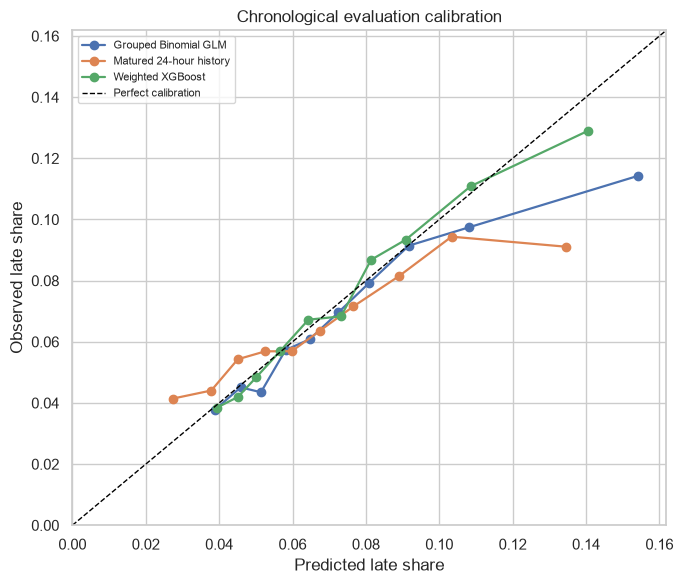

In [45]:
MODEL_DISPLAY_NAMES = {
    "Matured 24-hour history": "Matured 24-hour history",
    GLM_MODEL_NAME: GLM_MODEL_NAME,
    XGB_MODEL_NAME: XGB_MODEL_NAME,
}

figure, axis = plt.subplots(figsize=(7, 6))

# Plot observed against predicted risk within each calibration bin
for model_name, calibration_data in evaluation_calibration_df.groupby(
    "model_name"
):
    axis.plot(
        calibration_data["predicted_late_share"],
        calibration_data["observed_late_share"],
        marker="o",
        linewidth=1.6,
        label=MODEL_DISPLAY_NAMES[model_name],
    )

calibration_limit = 1.05 * max(
    evaluation_calibration_df[
        ["predicted_late_share", "observed_late_share"]
    ].max()
)
axis.plot(
    [0, calibration_limit],
    [0, calibration_limit],
    linestyle="--",
    color="black",
    linewidth=1,
    label="Perfect calibration",
)
axis.set_xlim(0, calibration_limit)
axis.set_ylim(0, calibration_limit)
axis.set_xlabel("Predicted late share")
axis.set_ylabel("Observed late share")
axis.set_title("Chronological evaluation calibration")
axis.legend(fontsize=8)
figure.tight_layout()
save_report_figure(figure, "wav_model_calibration")
plt.show()

## 9.3 Temporal, support, and weather robustness

Evaluate low-support sensitivity, HRRR forecast contribution, expanding monthly
performance, permutation importance, forecast-precipitation regimes, and GLM weather
associations without assigning causal meaning.

In [46]:
# Compare headline performance with and without Staten Island
low_support_metric_records = []

for scope_name, scope_mask in {
    "All five boroughs": pd.Series(True, index=evaluation_scoring_df.index),
    "Exclude Staten Island": evaluation_scoring_df["borough"].ne(
        "Staten Island"
    ),
}.items():
    low_support_metric_records.append(
        calculate_forecast_metrics(
            evaluation_scoring_df.loc[scope_mask],
            SELECTED_XGB_PREDICTION_COLUMN,
            SELECTED_XGB_MODEL_NAME,
            evaluation_group=scope_name,
        )
    )

low_support_summary_df = pd.DataFrame(low_support_metric_records)
low_support_summary_df[
    [
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,All five boroughs,114672,2.5885,5.2526
1,Exclude Staten Island,112924,2.4708,3.7779


### HRRR forecast feature ablation

Compare weighted XGBoost with and without the six issue-time HRRR summaries.
The ablation uses its own validation-selected tree count and remains separate from
the formal model comparison and operational diagnostics.

In [47]:
xgb_without_hrrr_evaluation_scoring_df = (
    evaluation_outcomes_df
    .merge(
        xgb_without_hrrr_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)
hrrr_feature_ablation_records = []
for (
    evaluation_period,
    scoring_data,
    prediction_column,
    feature_set,
    tree_count,
) in (
    (
        "Validation",
        xgb_validation_scoring_df,
        XGB_VALIDATION_PREDICTION_COLUMN,
        "With HRRR forecasts",
        XGB_TREE_COUNT,
    ),
    (
        "Validation",
        xgb_without_hrrr_validation_scoring_df,
        XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN,
        "Without HRRR forecasts",
        XGB_WITHOUT_HRRR_TREE_COUNT,
    ),
    (
        "Chronological evaluation",
        evaluation_scoring_df,
        XGB_PREDICTION_COLUMN,
        "With HRRR forecasts",
        XGB_TREE_COUNT,
    ),
    (
        "Chronological evaluation",
        xgb_without_hrrr_evaluation_scoring_df,
        XGB_WITHOUT_HRRR_PREDICTION_COLUMN,
        "Without HRRR forecasts",
        XGB_WITHOUT_HRRR_TREE_COUNT,
    ),
):
    metric_record = calculate_forecast_metrics(
        scoring_data,
        prediction_column,
        XGB_MODEL_NAME,
    )
    metric_record.update(
        {
            "evaluation_period": evaluation_period,
            "feature_set": feature_set,
            "selected_tree_count": tree_count,
        }
    )
    hrrr_feature_ablation_records.append(metric_record)

hrrr_feature_ablation_df = pd.DataFrame(
    hrrr_feature_ablation_records
).loc[
    :,
    [
        "evaluation_period",
        "feature_set",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "selected_tree_count",
    ],
]
hrrr_feature_ablation_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_hrrr_feature_ablation.csv",
    index=False,
)
hrrr_feature_ablation_df

,evaluation_period,feature_set,weighted_mae_percentage_points,weighted_rmse_percentage_points,selected_tree_count
0,Validation,With HRRR forecasts,2.5496,3.7250,125
1,Validation,Without HRRR forecasts,2.5075,3.6599,142
2,Chronological evaluation,With HRRR forecasts,2.5885,3.7164,125
3,Chronological evaluation,Without HRRR forecasts,2.6636,3.7266,142


In [48]:
# Freeze development-period monthly robustness folds
EXPANDING_BACKTEST_FOLDS = (
    (
        "July 2025",
        pd.Timestamp("2025-07-01"),
        pd.Timestamp("2025-08-01"),
    ),
    (
        "August 2025",
        pd.Timestamp("2025-08-01"),
        pd.Timestamp("2025-09-01"),
    ),
    (
        "September 2025",
        pd.Timestamp("2025-09-01"),
        pd.Timestamp("2025-10-01"),
    ),
    (
        "October 2025",
        pd.Timestamp("2025-10-01"),
        pd.Timestamp("2025-11-01"),
    ),
)

In [49]:
backtest_metric_records = []
backtest_source_df = add_borough_time_block(
    model_panel_df.loc[
        model_panel_df["split_label"].isin(
            ["training", "validation"]
        )
        & model_panel_df["target_observed"]
    ].copy()
)

# Expand the training window while holding out one later month per fold
for fold_name, evaluation_start, evaluation_end in (
    EXPANDING_BACKTEST_FOLDS
):
    backtest_training_df = backtest_source_df.loc[
        backtest_source_df["period_start"] < evaluation_start
    ].copy()
    backtest_evaluation_df = backtest_source_df.loc[
        backtest_source_df["period_start"].between(
            evaluation_start,
            evaluation_end,
            inclusive="left",
        )
    ].copy()

    training_borough_risk = (
        backtest_training_df
        .groupby("borough")
        .apply(
            lambda data: (
                data["late_trip_count"].sum()
                / data["wav_request_count"].sum()
            ),
            include_groups=False,
        )
    )
    training_global_risk = (
        backtest_training_df["late_trip_count"].sum()
        / backtest_training_df["wav_request_count"].sum()
    )
    persistence_predictions = (
        backtest_evaluation_df["rolling_24h_late_share"]
        .fillna(
            backtest_evaluation_df["borough"].map(
                training_borough_risk
            )
        )
        .fillna(training_global_risk)
    )
    xgb_backtest_fit = fit_fixed_xgboost_model(
        fitting_data=backtest_training_df,
        prediction_data=backtest_evaluation_df,
        categorical_features=XGB_CATEGORICAL_FEATURES,
        numeric_features=MODEL_NUMERIC_FEATURES,
        configuration=XGB_REGULARISED_CONFIGURATION,
        tree_count=XGB_TREE_COUNT,
    )

    fold_scoring_df = backtest_evaluation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ].copy()
    fold_scoring_df["backtest_persistence_prediction"] = (
        persistence_predictions.to_numpy()
    )
    fold_scoring_df["backtest_xgb_prediction"] = (
        xgb_backtest_fit["predictions"]
    )

    for model_name, prediction_column in {
        "Matured 24-hour history": (
            "backtest_persistence_prediction"
        ),
        XGB_MODEL_NAME: (
            "backtest_xgb_prediction"
        ),
    }.items():
        metric_record = calculate_forecast_metrics(
            fold_scoring_df,
            prediction_column,
            model_name,
            evaluation_group=fold_name,
        )
        metric_record.update(
            {
                "fold_name": fold_name,
                "training_end_exclusive": evaluation_start,
                "evaluation_end_exclusive": evaluation_end,
                "training_row_count": len(backtest_training_df),
            }
        )
        backtest_metric_records.append(metric_record)

expanding_backtest_metrics_df = pd.DataFrame(
    backtest_metric_records
)
expanding_backtest_metrics_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_expanding_backtest_metrics.csv",
    index=False,
)
expanding_backtest_metrics_df.pivot(
    index="fold_name",
    columns="model_name",
    values="weighted_mae_percentage_points",
)

model_name,Matured 24-hour history,Weighted XGBoost
fold_name,,
August 2025,3.5286,4.5231
July 2025,4.2403,4.5389
October 2025,2.7702,2.3685
September 2025,3.1718,2.7742


In [50]:
XGB_PREDICTOR_COLUMNS = (
    *XGB_CATEGORICAL_FEATURES,
    *MODEL_NUMERIC_FEATURES,
)
xgb_validation_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            xgb_validation_fit["preprocessor"],
        ),
        (
            "model",
            xgb_validation_fit["model"],
        ),
    ]
)
xgb_permutation_result = permutation_importance(
    xgb_validation_pipeline,
    model_validation_df.loc[:, XGB_PREDICTOR_COLUMNS],
    model_validation_df["late_share"],
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    n_jobs=1,
    random_state=RANDOM_SEED,
    sample_weight=model_validation_df["wav_request_count"],
)
xgb_permutation_importance_df = (
    pd.DataFrame(
        {
            "feature_name": XGB_PREDICTOR_COLUMNS,
            "importance_mean": (
                xgb_permutation_result.importances_mean
            ),
            "importance_standard_deviation": (
                xgb_permutation_result.importances_std
            ),
        }
    )
    .assign(
        importance_mean_percentage_points=lambda data: (
            100 * data["importance_mean"]
        ),
        importance_standard_deviation_percentage_points=(
            lambda data: (
                100 * data["importance_standard_deviation"]
            )
        ),
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
xgb_permutation_importance_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_xgboost_importance.csv",
    index=False,
)

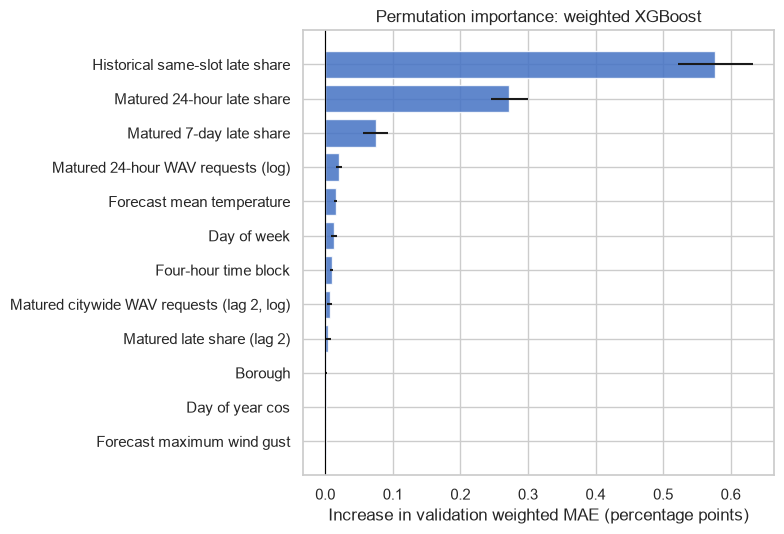

In [51]:
PERMUTATION_FEATURE_DISPLAY_NAMES = {
    "historical_same_slot_late_share": (
        "Historical same-slot late share"
    ),
    "rolling_24h_late_share": "Matured 24-hour late share",
    "rolling_7d_late_share": "Matured 7-day late share",
    "log1p_lag_2_citywide_wav_request_count": (
        "Matured citywide WAV requests (lag 2, log)"
    ),
    "log1p_rolling_24h_wav_request_count": (
        "Matured 24-hour WAV requests (log)"
    ),
    "log1p_lag_2_wav_request_count": (
        "Matured WAV requests (lag 2, log)"
    ),
    "lag_2_late_share": "Matured late share (lag 2)",
    "hrrr_forecast_mean_temperature_c": (
        "Forecast mean temperature"
    ),
    "hrrr_forecast_mean_relative_humidity_pct": (
        "Forecast mean relative humidity"
    ),
    "hrrr_forecast_total_precipitation_mm": (
        "Forecast total precipitation"
    ),
    "hrrr_forecast_any_rain": "Forecast any rain",
    "hrrr_forecast_mean_wind_speed_ms": (
        "Forecast mean wind speed"
    ),
    "hrrr_forecast_max_wind_gust_ms": (
        "Forecast maximum wind gust"
    ),
    "time_block": "Four-hour time block",
    "day_of_week": "Day of week",
    "borough": "Borough",
    "days_since_analysis_start": "Days since analysis start",
}

importance_plot_data = (
    xgb_permutation_importance_df.head(12)
    .sort_values("importance_mean_percentage_points")
)
importance_plot_data["feature_display_name"] = (
    importance_plot_data["feature_name"]
    .map(PERMUTATION_FEATURE_DISPLAY_NAMES)
    .fillna(
        importance_plot_data["feature_name"]
        .str.replace("_", " ", regex=False)
        .str.capitalize()
    )
)

figure, axis = plt.subplots(figsize=(8, 5.5))
axis.barh(
    importance_plot_data["feature_display_name"],
    importance_plot_data["importance_mean_percentage_points"],
    xerr=importance_plot_data[
        "importance_standard_deviation_percentage_points"
    ],
    color="#4472C4",
    alpha=0.85,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel(
    "Increase in validation weighted MAE (percentage points)"
)
axis.set_ylabel("")
axis.set_title("Permutation importance: weighted XGBoost")
figure.tight_layout()
save_report_figure(figure, "wav_permutation_importance")
plt.show()

In [52]:
# Diagnose validation performance across forecast-precipitation regimes
validation_diagnostic_df = model_validation_df[
    [
        *MODEL_KEY_COLUMNS,
        *MODEL_TARGET_COLUMNS,
        "hrrr_forecast_total_precipitation_mm",
    ]
].copy()
validation_diagnostic_df[GLM_VALIDATION_PREDICTION_COLUMN] = (
    glm_validation_fit["predictions"]
)
validation_diagnostic_df[XGB_VALIDATION_PREDICTION_COLUMN] = (
    xgb_validation_fit["predictions"]
)
forecast_precipitation = validation_diagnostic_df[
    "hrrr_forecast_total_precipitation_mm"
]
validation_diagnostic_df["forecast_weather_regime"] = (
    np.select(
        [
            forecast_precipitation.eq(0),
            forecast_precipitation.le(1),
        ],
        ["Dry forecast", "Up to 1 mm forecast"],
        default="More than 1 mm forecast",
    )
)

weather_regime_metric_records = []
for weather_regime, regime_data in (
    validation_diagnostic_df.groupby(
        "forecast_weather_regime",
        observed=True,
    )
):
    for model_name, prediction_column in {
        GLM_MODEL_NAME: GLM_VALIDATION_PREDICTION_COLUMN,
        XGB_MODEL_NAME: XGB_VALIDATION_PREDICTION_COLUMN,
    }.items():
        metric_record = calculate_forecast_metrics(
            regime_data,
            prediction_column,
            model_name,
            evaluation_group=str(weather_regime),
        )
        metric_record["observed_late_share_percentage"] = (
            100 * metric_record["observed_weighted_late_share"]
        )
        weather_regime_metric_records.append(metric_record)

weather_regime_metrics_df = pd.DataFrame(
    weather_regime_metric_records
)
weather_regime_metrics_df[
    [
        "model_name",
        "evaluation_group",
        "row_count",
        "wav_request_count",
        "observed_late_share_percentage",
        "weighted_mae_percentage_points",
    ]
]

,model_name,evaluation_group,row_count,wav_request_count,observed_late_share_percentage,weighted_mae_percentage_points
0,Grouped Binomial GLM,Dry forecast,1430,102635,6.5231,2.5348
1,Weighted XGBoost,Dry forecast,1430,102635,6.5231,2.4752
2,Grouped Binomial GLM,More than 1 mm forecast,103,5528,6.3857,3.7990
3,Weighted XGBoost,More than 1 mm forecast,103,5528,6.3857,3.5581
4,Grouped Binomial GLM,Up to 1 mm forecast,201,12253,6.5698,2.6686
5,Weighted XGBoost,Up to 1 mm forecast,201,12253,6.5698,2.7175


In [53]:
# Summarise standardised HRRR associations from the grouped-binomial GLM
glm_weather_confidence_intervals = final_glm_result.conf_int()
glm_weather_associations_df = pd.DataFrame(
    {
        "feature_name": HRRR_FORECAST_MODEL_FEATURES,
        "standardised_log_odds_coefficient": [
            final_glm_result.params[feature_name]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "confidence_interval_lower": [
            glm_weather_confidence_intervals.loc[feature_name, 0]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "confidence_interval_upper": [
            glm_weather_confidence_intervals.loc[feature_name, 1]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "p_value": [
            final_glm_result.pvalues[feature_name]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
    }
)
glm_weather_associations_df[
    "odds_ratio_per_training_standard_deviation"
] = np.exp(
    glm_weather_associations_df[
        "standardised_log_odds_coefficient"
    ]
)
glm_weather_associations_df

,feature_name,standardised_log_odds_coefficient,confidence_interval_lower,confidence_interval_upper,p_value,odds_ratio_per_training_standard_deviation
0,hrrr_forecast_mean_temperature_c,0.1398,0.0627,0.2168,0.0004,1.1500
1,hrrr_forecast_mean_relative_humidity_pct,0.0217,-0.0168,0.0602,0.2697,1.0219
2,hrrr_forecast_total_precipitation_mm,0.0537,0.0367,0.0707,0.0000,1.0552
3,hrrr_forecast_any_rain,0.0182,-0.0104,0.0468,0.2118,1.0184
4,hrrr_forecast_mean_wind_speed_ms,-0.0076,-0.0794,0.0643,0.8361,0.9924
5,hrrr_forecast_max_wind_gust_ms,0.0084,-0.0714,0.0883,0.8357,1.0085
